# 원하는 포즈로 이미지 만드는 도구 (Colab + ComfyUI)

사람 사진 한 장을 올리면 그 사람의 **자세(관절 위치)** 를 뽑아 내고, 프롬프트가 묘사하는 **다른 인물·장면을 같은 자세로** 그려 주는 도구를 만드는 튜토리얼입니다.

출발점은 교안의 **FLUX.2-klein-4B (GGUF Q4) + ComfyUI** 노트입니다. 그 위에 **OpenPose(포즈 추출)** 와 **ControlNet(포즈 조건)** 을 얹었습니다.

---

## 학습 목표
- 참조 사진에서 **OpenPose 로 관절(뼈대)** 을 뽑는 과정을 이해합니다.
- **ControlNet** 이 뼈대 그림을 생성 조건으로 넣어 자세를 고정하는 원리를 직접 확인합니다.
- **같은 포즈·다른 프롬프트 / 다른 포즈·같은 프롬프트** 실험으로 무엇이 결과를 좌우하는지 관찰합니다.
- ComfyUI 워크플로우를 **API(JSON)** 로 조립해 재사용 가능한 함수로 만듭니다.

---

## 왜 이 구성인가? (핵심 개념)

| 시도 | 결과 | 이유 |
|---|---|---|
| FLUX.2-klein 4B 에 포즈 ControlNet | 불가 | 2026-07 기준 BFL 공식 FLUX.2 ControlNet 이 없음 |
| FLUX.1-dev ControlNet Union | 무료 T4 에서 무리 | 12B 모델이라 메모리 부족, 비상업 라이선스 |
| **SD 1.5 + ControlNet OpenPose** | **채택** | 무료 T4 에서 안정적으로 동작, 포즈 조건 생태계가 가장 성숙 |
| klein 의 참조 이미지 편집(ReferenceLatent) | 비교 실험용 | 별도 설치 없이 되지만 ControlNet 만큼 정밀하지 않음 |

그래서 이 노트는 **두 모델을 함께** 씁니다.
- **FLUX.2-klein-4B**: 포즈 조건 없이 프롬프트만으로 그린 결과(비교 기준)와 참조 이미지 실험
- **SD 1.5 + ControlNet OpenPose**: 포즈를 그대로 따르는 실제 도구

---

## 파이프라인 한눈에 보기

```
참조 사진 ──▶ OpenPose ──▶ 뼈대 이미지 ──┐
                                          ├──▶ ControlNet ──▶ SD 1.5 ──▶ 같은 자세의 새 이미지
프롬프트 ──▶ 텍스트 인코더 ───────────────┘
```

| 역할 | 파일 | 설명 |
|---|---|---|
| 포즈 추출기 | `lllyasviel/Annotators` (controlnet_aux 가 자동 다운로드) | 사진에서 몸·손·얼굴 관절을 찾아 뼈대 그림으로 그림 |
| 포즈 조건 회로 | `control_v11p_sd15_openpose_fp16.safetensors` (0.7GB) | 뼈대 그림을 읽어 생성 과정에 자세 정보를 주입 |
| 생성 모델 | `v1-5-pruned-emaonly-fp16.safetensors` (2.1GB) | 텍스트 인코더·디퓨전·VAE 가 한 파일에 들어 있는 SD 1.5 |
| 비교용 모델 | FLUX.2-klein-4B 3종 (약 11GB) | 교안 노트와 동일 |

---

## 라이선스 확인

| 구성 요소 | 라이선스 | 메모 |
|---|---|---|
| FLUX.2-klein-4B | Apache 2.0 | 상업 이용 가능 |
| Stable Diffusion 1.5 | CreativeML OpenRAIL-M | 사용 제한 조항(유해 용도 금지) 준수 |
| ControlNet v1.1 OpenPose | OpenRAIL | SD 1.5 와 같은 계열 |
| OpenPose 포즈 추출 모델 | CMU OpenPose 계열, 비상업·학술용 | 이 과제는 교육 목적이므로 사용 가능 |

---

## 실습 준비와 실행 순서
1. 상단 메뉴 **[런타임 → 런타임 유형 변경 → T4 GPU]** 선택 후 저장
2. 아래 셀을 **1번부터 순서대로** 실행합니다. 모델 다운로드(약 14GB)에 시간이 걸립니다.
3. **[단계 7]** 과 **[단계 10-B]** 에서는 사람 사진을 직접 업로드합니다. 전신이 크게 나온 사진일수록 뼈대가 잘 잡힙니다.
4. 결과는 모두 `/content/samples/` 에 저장되고, **[단계 12]** 에서 zip 으로 내려받습니다.

## [단계 1] 런타임에 GPU 가 있는지 확인

이 실습은 GPU(그래픽카드) 없이는 실행할 수 없습니다. 현재 Colab 런타임이 GPU 를 인식하고 있는지, 인식한다면 어떤 종류(T4 등)이고 VRAM(비디오 메모리)은 얼마인지 확인합니다.

GPU가 감지되지 않으면 상단 메뉴 **[런타임 → 런타임 유형 변경 → T4 GPU]** 로 바꾼 뒤 이 셀을 다시 실행해야 합니다.

In [1]:
# 1) GPU 가 사용 가능한지 확인
import torch

print("PyTorch 버전:", torch.__version__)
print("CUDA 사용 가능:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM(GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
else:
    raise RuntimeError("GPU가 없습니다. [런타임 → 런타임 유형 변경 → T4 GPU] 후 다시 실행하세요.")

PyTorch 버전: 2.14.1+cu130
CUDA 사용 가능: True
GPU: Tesla T4
VRAM(GB): 15.64


## [단계 2] ComfyUI 본체와 GGUF 노드 설치

**ComfyUI** 는 노드(node) 기반의 이미지 생성 도구로, 각 기능(모델 로드, 텍스트 인코딩, 샘플링 등)을 블록처럼 연결해 파이프라인을 구성합니다. 이 실습에서는 ComfyUI 를 **웹 UI 없이 API 서버로만** 사용합니다.

여기에 더해 **ComfyUI-GGUF** 라는 커스텀 노드(플러그인)를 설치합니다. ComfyUI 기본 기능은 GGUF 포맷을 읽지 못하기 때문에, 양자화 모델을 로드하려면 이 플러그인이 필요합니다.

마지막으로 사진에서 관절을 뽑는 **controlnet_aux** 라이브러리도 함께 설치합니다. OpenPose 포즈 추출기가 이 안에 들어 있습니다.


In [2]:
# 2) ComfyUI 본체 + GGUF 노드(플러그인) + 포즈 추출 라이브러리 설치
import os

%cd /content
if not os.path.isdir("/content/ComfyUI"):
    !git clone https://github.com/comfyanonymous/ComfyUI.git   # ComfyUI 본체

%cd /content/ComfyUI
!pip install -q -r requirements.txt                            # ComfyUI 의존성

# GGUF 파일을 읽기 위한 커스텀 노드 설치
%cd /content/ComfyUI/custom_nodes
if not os.path.isdir("ComfyUI-GGUF"):
    !git clone https://github.com/city96/ComfyUI-GGUF.git      # GGUF 로더 노드
%cd /content/ComfyUI
!pip install -q gguf                                           # GGUF 파싱 라이브러리
!pip install -q controlnet_aux                                 # OpenPose 포즈 추출 라이브러리

print("\n완료: ComfyUI + GGUF 노드 + controlnet_aux 설치")

/content
Cloning into 'ComfyUI'...
remote: Enumerating objects: 65068, done.
remote: Counting objects: 100% (864/864), done.
remote: Compressing objects: 100% (251/251), done.
remote: Total 65068 (delta 741), reused 613 (delta 613), pack-reused 64204 (from 2)
Receiving objects: 100% (65068/65068), 99.81 MiB | 19.45 MiB/s, done.
Resolving deltas: 100% (45054/45054), done.
/content/ComfyUI
/content/ComfyUI/custom_nodes
Cloning into 'ComfyUI-GGUF'...
remote: Enumerating objects: 814, done.
remote: Counting objects: 100% (570/570), done.
remote: Compressing objects: 100% (206/206), done.
remote: Total 814 (delta 515), reused 364 (delta 364), pack-reused 244 (from 1)
Receiving objects: 100% (814/814), 187.82 KiB | 8.17 MiB/s, done.
Resolving deltas: 100% (545/545), done.
/content/ComfyUI

완료: ComfyUI + GGUF 노드 + controlnet_aux 설치


## [단계 3] 모델 파일 3종 다운로드

위 개요에서 설명한 대로, FLUX.2-klein 파이프라인은 **세 가지 파일**로 구성됩니다. 각 파일을 ComfyUI 가 정해둔 표준 폴더에 다운로드합니다.

- **디퓨전 모델** (2.6GB) - GGUF Q4 양자화본. 이미지 생성의 핵심 두뇌
- **텍스트 인코더** (8GB) - Qwen3-4B. 프롬프트를 숫자로 변환
- **VAE** (330MB) - latent 를 사람이 보는 픽셀 이미지로 복원

이미 받은 파일은 건너뛰도록 되어 있어, 런타임이 끊기고 다시 실행해도 처음부터 받지 않습니다. 총 약 11GB 로 시간이 꽤 걸립니다.

In [3]:
# 3) 파이프라인 구성 파일 3종 다운로드 → ComfyUI 표준 폴더에 배치
import os
%cd /content/ComfyUI

# ComfyUI 가 모델을 찾는 표준 경로 생성
os.makedirs("models/diffusion_models", exist_ok=True)   # 디퓨전 모델
os.makedirs("models/text_encoders",  exist_ok=True)   # 텍스트 인코더
os.makedirs("models/vae",            exist_ok=True)   # VAE

def 다운로드(url, 저장경로):
    """이미 받았으면 건너뛰고, 아니면 wget 로 받는 헬퍼"""
    if os.path.exists(저장경로) and os.path.getsize(저장경로) > 1_000_000:
        print(f"  ↳ 이미 있음: {저장경로} ({os.path.getsize(저장경로)/1e9:.2f} GB)")
        return
    print(f"  ↳ 다운로드 중...")
    !wget -q --show-progress -O "{저장경로}" "{url}"

print("[1/3] 디퓨전 모델 (GGUF Q4, 약 2.6GB)")
다운로드("https://huggingface.co/unsloth/FLUX.2-klein-4B-GGUF/resolve/main/flux-2-klein-4b-Q4_K_M.gguf",
        "models/diffusion_models/flux-2-klein-4b-Q4_K_M.gguf")

print("[2/3] 텍스트 인코더 (Qwen3-4B, 약 8GB)")
다운로드("https://huggingface.co/Comfy-Org/vae-text-encorder-for-flux-klein-4b/resolve/main/split_files/text_encoders/qwen_3_4b.safetensors",
        "models/text_encoders/qwen_3_4b.safetensors")

print("[3/3] VAE (약 330MB)")
다운로드("https://huggingface.co/Comfy-Org/vae-text-encorder-for-flux-klein-4b/resolve/main/split_files/vae/flux2-vae.safetensors",
        "models/vae/flux2-vae.safetensors")

print("\n다운로드 완료. 배치된 파일 확인:")
!ls -lh models/diffusion_models/flux-2-klein-4b-Q4_K_M.gguf \
      models/text_encoders/qwen_3_4b.safetensors \
      models/vae/flux2-vae.safetensors

/content/ComfyUI
[1/3] 디퓨전 모델 (GGUF Q4, 약 2.6GB)
  ↳ 다운로드 중...
models/diffusion_mo 100%[===================>]   2.42G  51.0MB/s    in 34s     
[2/3] 텍스트 인코더 (Qwen3-4B, 약 8GB)
  ↳ 다운로드 중...
models/text_encoder 100%[===================>]   7.49G  48.1MB/s    in 2m 41s  
[3/3] VAE (약 330MB)
  ↳ 다운로드 중...
models/vae/flux2-va 100%[===================>] 320.64M  85.7MB/s    in 4.0s    

다운로드 완료. 배치된 파일 확인:
-rw-r--r-- 1 root root 2.5G Nov 11 06:51 models/diffusion_models/flux-2-klein-4b-Q4_K_M.gguf
-rw-r--r-- 1 root root 7.5G Nov 11 06:54 models/text_encoders/qwen_3_4b.safetensors
-rw-r--r-- 1 root root 321M Nov 11 06:54 models/vae/flux2-vae.safetensors


## [단계 4] 포즈용 모델 2종 다운로드 (SD 1.5 + ControlNet OpenPose)

포즈를 따르는 그림은 **SD 1.5** 와 **ControlNet OpenPose** 조합으로 만듭니다.

- **SD 1.5 체크포인트** (2.1GB): 텍스트 인코더·디퓨전 모델·VAE 가 한 파일에 들어 있습니다. 그래서 klein 처럼 세 파일로 나눠 받을 필요가 없습니다.
- **ControlNet OpenPose** (0.7GB): 뼈대 그림을 읽어 "이 자세로 그려라" 라는 조건을 생성 과정에 넣는 보조 회로입니다.

둘 다 fp16(16비트) 버전이라 원본보다 절반 크기입니다. 앞 셀의 `다운로드()` 헬퍼를 그대로 재사용합니다.

In [4]:
# 4) 포즈 도구용 모델 2종 다운로드 → ComfyUI 표준 폴더에 배치
%cd /content/ComfyUI
os.makedirs("models/checkpoints", exist_ok=True)   # SD 1.5 같은 올인원 체크포인트
os.makedirs("models/controlnet",  exist_ok=True)   # ControlNet 보조 회로

print("[1/2] SD 1.5 체크포인트 (fp16, 약 2.1GB)")
다운로드("https://huggingface.co/Comfy-Org/stable-diffusion-v1-5-archive/resolve/main/v1-5-pruned-emaonly-fp16.safetensors",
        "models/checkpoints/v1-5-pruned-emaonly-fp16.safetensors")

print("[2/2] ControlNet OpenPose (fp16, 약 0.7GB)")
다운로드("https://huggingface.co/comfyanonymous/ControlNet-v1-1_fp16_safetensors/resolve/main/control_v11p_sd15_openpose_fp16.safetensors",
        "models/controlnet/control_v11p_sd15_openpose_fp16.safetensors")

print("\n다운로드 완료. 배치된 파일 확인:")
!ls -lh models/checkpoints/v1-5-pruned-emaonly-fp16.safetensors \
      models/controlnet/control_v11p_sd15_openpose_fp16.safetensors

/content/ComfyUI
[1/2] SD 1.5 체크포인트 (fp16, 약 2.1GB)
  ↳ 다운로드 중...
models/checkpoints/ 100%[===================>]   1.99G  91.5MB/s    in 21s     
[2/2] ControlNet OpenPose (fp16, 약 0.7GB)
  ↳ 다운로드 중...
models/controlnet/c 100%[===================>] 689.13M   118MB/s    in 8.6s    

다운로드 완료. 배치된 파일 확인:
-rw-r--r-- 1 root root 2.0G Nov 11 06:54 models/checkpoints/v1-5-pruned-emaonly-fp16.safetensors
-rw-r--r-- 1 root root 690M Nov 11 06:54 models/controlnet/control_v11p_sd15_openpose_fp16.safetensors


## [단계 5] ComfyUI 서버 실행

ComfyUI 를 **백그라운드 프로세스**로 띄웁니다. 이 서버는 Colab 컨테이너 내부의 `http://127.0.0.1:8188` 에서 HTTP API 로 동작하며, 이후 단계의 생성 함수들이 모두 이 서버에 워크플로우를 보내는 구조입니다.

실행 후 `http 200` 응답이 확인되면 서버가 준비된 것입니다. 이 셀이 실행 중인 동안 서버가 계속 유지됩니다.

> 새 모델 파일을 추가로 받았다면 이 셀을 다시 실행해 서버를 재시작해야 ComfyUI 가 파일 목록을 새로 읽습니다.


In [5]:
# 5) ComfyUI 서버를 백그라운드로 실행 (이후 모든 생성 함수가 이 서버에 접속함)
#    ※ Gradio 를 쓰므로 외부 공개 터널은 필요 없습니다.
import subprocess, os, time

%cd /content/ComfyUI

# 혹시 떠 있는 예전 서버가 있으면 정리
!pkill -f "main.py" 2>/dev/null
time.sleep(2)

# ComfyUI 백그라운드 실행 (포트 8188)
os.system("nohup python main.py --listen 0.0.0.0 --port 8188 > /content/comfyui.log 2>&1 &")

# 서버가 뜰 때까지 대기 (로컬에서 200 응답이 오면 준비 완료)
print("ComfyUI 기동 대기 중...")
for _ in range(40):
    time.sleep(1)
    code = subprocess.run("curl -s -o /dev/null -w '%{http_code}' http://127.0.0.1:8188/",
                          shell=True, capture_output=True, text=True).stdout
    if code == "200":
        print("완료: ComfyUI 서버 준비 (http://127.0.0.1:8188)")
        break
else:
    print("서버가 안 뜹니다. 로그:")
    print(open("/content/comfyui.log").read()[-800:])

/content/ComfyUI
^C
ComfyUI 기동 대기 중...
완료: ComfyUI 서버 준비 (http://127.0.0.1:8188)


## [단계 6] 공통 도우미 함수 만들기

원본 노트의 `generate()` 안에 있던 **"워크플로우 전송 → 완료될 때까지 확인 → 이미지 받아오기"** 부분을 따로 떼어 `run_workflow()` 로 만듭니다. 이렇게 하면 klein 워크플로우와 포즈 워크플로우가 같은 함수를 함께 쓸 수 있습니다.

- `run_workflow(workflow, save_node, save_as)`: 워크플로우(JSON)를 ComfyUI 에 보내고 결과를 PIL 이미지로 돌려줍니다. `save_as` 를 주면 `samples/` 에 저장합니다.
- `side_by_side(*images)`: 여러 장을 같은 높이로 맞춰 가로로 붙입니다. 참조 사진·뼈대·결과를 한눈에 비교할 때 씁니다.

In [6]:
# 6) ComfyUI 호출 공통 함수 + 비교용 이미지 붙이기 함수
import requests, time, json, urllib.parse, io, os
from PIL import Image
from IPython.display import display

SERVER      = "http://127.0.0.1:8188"        # Colab 안의 ComfyUI 서버 주소
COMFY_INPUT = "/content/ComfyUI/input"       # ComfyUI 의 LoadImage 노드가 그림을 찾는 폴더
SAMPLES     = "/content/samples"             # 과제 제출용 결과 폴더
os.makedirs(COMFY_INPUT, exist_ok=True)
os.makedirs(SAMPLES, exist_ok=True)

def run_workflow(workflow, save_node, save_as=None, timeout_s=360):
    """워크플로우 JSON 을 ComfyUI 에 보내고, 완성된 이미지를 PIL 로 돌려줍니다."""
    # ① 생성 요청
    r = requests.post(f"{SERVER}/prompt", json={"prompt": workflow, "client_id": "colab"}, timeout=30)
    if r.status_code != 200:
        raise RuntimeError(f"요청 실패 {r.status_code}: {r.text[:500]}")
    pid = r.json()["prompt_id"]

    # ② 끝날 때까지 2초마다 확인 (폴링)
    t0 = time.time()
    while time.time() - t0 < timeout_s:
        time.sleep(2)
        try:
            h = requests.get(f"{SERVER}/history/{pid}", timeout=10).json()
        except Exception:
            continue
        if pid not in h:
            continue
        entry = h[pid]
        if entry.get("status", {}).get("status_str") == "error":
            raise RuntimeError("ComfyUI 실행 에러: " + json.dumps(entry["status"].get("messages", []), ensure_ascii=False)[:800])
        imgs = entry.get("outputs", {}).get(save_node, {}).get("images", [])
        if not imgs:
            raise RuntimeError("결과 이미지 없음")

        # ③ 결과 이미지 받아오기
        info = imgs[0]
        q = urllib.parse.urlencode({"filename": info["filename"], "subfolder": info.get("subfolder", ""),
                                    "type": info.get("type", "output")})
        img = Image.open(io.BytesIO(requests.get(f"{SERVER}/view?{q}", timeout=30).content)).convert("RGB")
        if save_as:
            img.save(os.path.join(SAMPLES, save_as))
        print(f"완료 ({time.time() - t0:.1f}초)" + (f" → samples/{save_as}" if save_as else ""))
        return img
    raise TimeoutError(f"{timeout_s}초 안에 끝나지 않았습니다. /content/comfyui.log 를 확인하세요.")

def side_by_side(*imgs, h=384):
    """여러 이미지를 같은 높이로 맞춰 가로로 이어 붙입니다."""
    resized = [im.resize((max(1, int(im.width * h / im.height)), h)) for im in imgs]
    canvas = Image.new("RGB", (sum(im.width for im in resized), h), "white")
    x = 0
    for im in resized:
        canvas.paste(im, (x, 0))
        x += im.width
    return canvas

print("준비 완료: run_workflow(), side_by_side()")

준비 완료: run_workflow(), side_by_side()


## [단계 7] 참조 사진 업로드와 포즈 추출

자세를 따올 **사람 사진** 을 올리면, OpenPose 가 몸·손·얼굴의 관절 위치를 찾아 **검은 바탕의 뼈대 그림** 으로 그려 줍니다. 이 뼈대 그림이 다음 단계에서 ControlNet 의 입력이 됩니다.

- 실행하면 **[파일 선택]** 버튼이 나옵니다. 사진을 한 장 고르세요.
- 원본 사진은 `samples/ref_01.jpg`, 뼈대 그림은 `samples/pose_01.png` 로 저장됩니다. 뼈대 그림은 ComfyUI 입력 폴더에도 복사됩니다.
- 이 저장소는 공개되므로 **본인 사진이나 Unsplash·Pexels 같은 무료 라이선스 사진** 을 쓰세요.

> 뼈대 그림이 새까맣게만 나오면 사람을 못 찾은 것입니다. 사람이 화면에 더 크게, 몸 전체가 보이게 찍힌 사진으로 바꿔 보세요.

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/controlnet_aux/mediapipe_face/mediapipe_face_common.py:7: UserWarning: The module 'mediapipe' is not installed. The package will have limited functionality. Please install it using the command: pip install 'mediapipe'
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarni

body_pose_model.pth: reconstructing file:   0%|          |  0.00B /  209MB            

body_pose_model.pth: downloading bytes:           |  0.00B            

hand_pose_model.pth: reconstructing file:   0%|          |  0.00B /  147MB            

hand_pose_model.pth: downloading bytes:           |  0.00B            

facenet.pth: reconstructing file:   0%|          |  0.00B /  154MB            

facenet.pth: downloading bytes:           |  0.00B            

Saving pexels-gabriel-machado-65216414-35452275.jpg to pexels-gabriel-machado-65216414-35452275.jpg
뼈대 저장: samples/pose_01.png  (512×768)


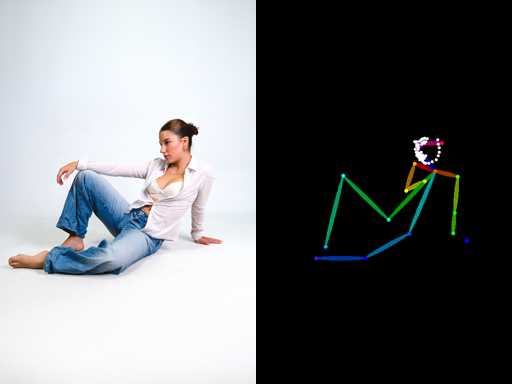

In [7]:
# 7) 참조 사진 업로드 → OpenPose 로 관절(뼈대) 추출 → samples/ 와 ComfyUI 입력 폴더에 저장
from google.colab import files
from controlnet_aux import OpenposeDetector

openpose = OpenposeDetector.from_pretrained("lllyasviel/Annotators")   # 포즈 추출 모델 (처음 한 번 다운로드)

def upload_photo(save_name):
    """[파일 선택] 으로 사진 한 장을 받아 samples/ 에 저장하고 PIL 이미지로 돌려줍니다."""
    up = files.upload()
    fname = next(iter(up))
    photo = Image.open(io.BytesIO(up[fname])).convert("RGB")
    photo.save(os.path.join(SAMPLES, save_name))
    return photo

def extract_pose(photo, name):
    """사진 → 뼈대 그림. samples/{name}.png 와 ComfyUI/input/{name}.png 에 저장합니다."""
    pose = openpose(photo, detect_resolution=512, image_resolution=512,
                    include_body=True, include_hand=True, include_face=True)
    if pose.getbbox() is None:   # 전부 검은색 = 사람을 못 찾음
        print("경고: 사람을 찾지 못했습니다. 전신이 크게 나온 다른 사진을 써 보세요.")
    pose.save(os.path.join(SAMPLES, f"{name}.png"))
    pose.save(os.path.join(COMFY_INPUT, f"{name}.png"))
    print(f"뼈대 저장: samples/{name}.png  ({pose.width}×{pose.height})")
    return pose

ref1  = upload_photo("ref_01.jpg")
pose1 = extract_pose(ref1, "pose_01")
display(side_by_side(ref1, pose1))

## [단계 8] 포즈 조건으로 이미지 생성 (도구의 핵심)

ComfyUI 워크플로우를 이렇게 연결합니다.

```
CheckpointLoader(SD 1.5) ─┬─ CLIPTextEncode(프롬프트) ───┐
                          └─ CLIPTextEncode(네거티브) ───┤
LoadImage(뼈대) ── ControlNetLoader ── ControlNetApply ──┴─▶ KSampler ─▶ VAEDecode ─▶ SaveImage
```

klein 워크플로우와 달라진 점은 **ControlNetApply** 노드 하나입니다. 이 노드가 프롬프트 조건에 뼈대 정보를 덧붙여, 샘플러가 매 스텝 "이 자세" 쪽으로 그림을 끌고 가게 만듭니다.

주요 인자
- `strength`: 포즈를 따르는 힘. 1.0 이 기본이고, 낮출수록 프롬프트가 자세를 더 바꿀 수 있습니다.
- `cfg = 7.0`, `steps = 25`: SD 1.5 는 **증류(distillation)를 거치지 않은 모델** 이라 CFG 를 켜고 스텝을 넉넉히 줘야 합니다. 증류된 klein 이 `cfg 1.0`, `4 스텝` 으로 충분한 것과 대비됩니다.
- 해상도는 뼈대 그림 크기를 그대로 씁니다(짧은 변 512). SD 1.5 가 학습한 크기라 가장 안정적입니다.

완료 (24.3초) → samples/output_01.png


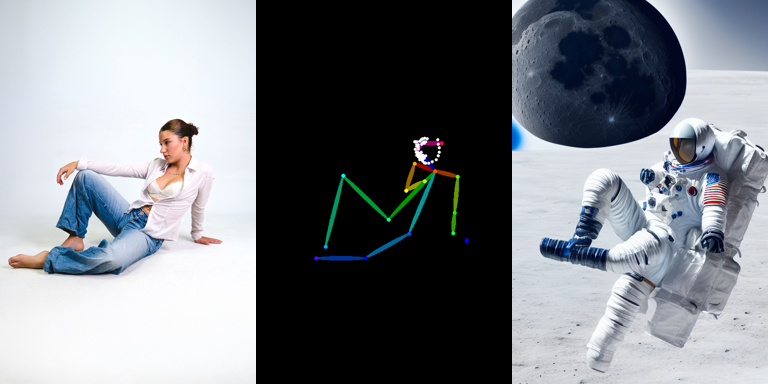

In [8]:
# 8) 포즈 조건 생성 함수 정의 → 첫 결과(output_01.png) 만들기
SD_CKPT     = "v1-5-pruned-emaonly-fp16.safetensors"
POSE_CN     = "control_v11p_sd15_openpose_fp16.safetensors"
NEG_DEFAULT = "lowres, blurry, bad anatomy, extra limbs, extra fingers, deformed hands, watermark, text"

def pose_generate(pose_name, prompt, save_as=None, negative=NEG_DEFAULT,
                  strength=1.0, steps=25, cfg=7.0, seed=42):
    """뼈대 그림(pose_name) + 프롬프트 → 같은 자세의 새 이미지"""
    w, h = Image.open(os.path.join(COMFY_INPUT, f"{pose_name}.png")).size
    workflow = {
      "1":  {"class_type": "CheckpointLoaderSimple", "inputs": {"ckpt_name": SD_CKPT}},                 # SD 1.5 로드 (MODEL, CLIP, VAE)
      "2":  {"class_type": "CLIPTextEncode", "inputs": {"text": prompt,   "clip": ["1", 1]}},           # 프롬프트 인코딩
      "3":  {"class_type": "CLIPTextEncode", "inputs": {"text": negative, "clip": ["1", 1]}},           # 네거티브 인코딩
      "4":  {"class_type": "LoadImage", "inputs": {"image": f"{pose_name}.png"}},                       # 뼈대 그림 불러오기
      "5":  {"class_type": "ControlNetLoader", "inputs": {"control_net_name": POSE_CN}},                # ControlNet 로드
      "6":  {"class_type": "ControlNetApplyAdvanced", "inputs": {                                       # 조건에 포즈 덧붙이기
                 "positive": ["2", 0], "negative": ["3", 0], "control_net": ["5", 0], "image": ["4", 0],
                 "strength": float(strength), "start_percent": 0.0, "end_percent": 1.0}},
      "7":  {"class_type": "EmptyLatentImage", "inputs": {"width": w, "height": h, "batch_size": 1}},  # 빈 캔버스
      "8":  {"class_type": "KSampler", "inputs": {                                                      # 실제 생성
                 "seed": int(seed), "steps": int(steps), "cfg": float(cfg),
                 "sampler_name": "dpmpp_2m", "scheduler": "karras", "denoise": 1.0,
                 "model": ["1", 0], "positive": ["6", 0], "negative": ["6", 1], "latent_image": ["7", 0]}},
      "9":  {"class_type": "VAEDecode", "inputs": {"samples": ["8", 0], "vae": ["1", 2]}},             # latent → 이미지
      "10": {"class_type": "SaveImage", "inputs": {"images": ["9", 0], "filename_prefix": "pose_tool"}},
    }
    return run_workflow(workflow, "10", save_as)

PROMPT_1 = "a female astronaut in a white spacesuit standing on the moon, full body, photo, highly detailed"
out1 = pose_generate("pose_01", PROMPT_1, "output_01.png")
display(side_by_side(ref1, pose1, out1))   # 참조 사진 | 뼈대 | 결과

## [단계 9] 비교 기준: 포즈 조건 없이 klein 으로만 그리기

포즈 조건이 정말 일을 하고 있는지 확인하려면 **조건이 없을 때** 와 비교해야 합니다. 같은 프롬프트를 원본 노트의 klein 워크플로우로 그려 봅니다.

> 원본 노트에서 하나를 고쳤습니다. KSampler 의 `cfg` 를 **4.0 → 1.0** 으로 바꿨습니다. FLUX.2-klein-4B 는 증류된 모델이라 권장값이 `cfg 1.0`, `4 스텝` 입니다. 4.0 으로 두면 계산이 두 배로 들고(조건 있는 버전·없는 버전을 둘 다 계산) 색이 과하게 탈 수 있습니다.

`reference_pose` 인자는 [단계 10-D] 실험에서 씁니다.

완료 (62.3초) → samples/baseline_klein_no_pose.png


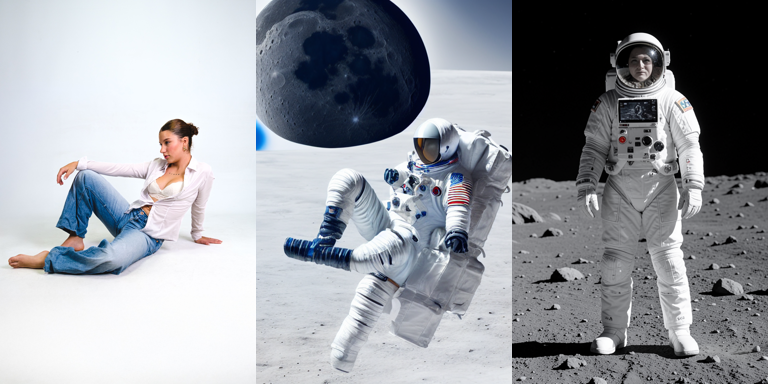

In [9]:
# 9) klein 생성 함수 (원본 노트의 워크플로우, cfg 1.0 으로 수정) → 포즈 조건 없는 비교 결과 만들기
def klein_generate(prompt, save_as=None, width=768, height=1024, steps=4, seed=42, reference_pose=None):
    """FLUX.2-klein-4B 로 생성. reference_pose 를 주면 그 그림을 참조 이미지로 함께 넣습니다."""
    workflow = {
      "10": {"class_type": "UnetLoaderGGUF",   "inputs": {"unet_name": "flux-2-klein-4b-Q4_K_M.gguf"}},
      "8":  {"class_type": "CLIPLoader",       "inputs": {"clip_name": "qwen_3_4b.safetensors", "type": "flux2"}},
      "6":  {"class_type": "CLIPTextEncode",   "inputs": {"text": prompt, "clip": ["8", 0]}},
      "7":  {"class_type": "CLIPTextEncode",   "inputs": {"text": "", "clip": ["8", 0]}},
      "5":  {"class_type": "EmptyLatentImage", "inputs": {"width": int(width), "height": int(height), "batch_size": 1}},
      "3":  {"class_type": "KSampler",         "inputs": {"seed": int(seed), "steps": int(steps), "cfg": 1.0,   # 증류 모델 권장값
                                                          "sampler_name": "euler", "scheduler": "simple", "denoise": 1.0,
                                                          "model": ["10", 0], "positive": ["6", 0],
                                                          "negative": ["7", 0], "latent_image": ["5", 0]}},
      "4":  {"class_type": "VAELoader",        "inputs": {"vae_name": "flux2-vae.safetensors"}},
      "9":  {"class_type": "VAEDecode",        "inputs": {"samples": ["3", 0], "vae": ["4", 0]}},
      "11": {"class_type": "SaveImage",        "inputs": {"images": ["9", 0], "filename_prefix": "flux2_klein"}},
    }
    if reference_pose:   # 참조 이미지 모드: 그림을 latent 로 바꿔 프롬프트 조건에 붙임
        workflow["20"] = {"class_type": "LoadImage",       "inputs": {"image": f"{reference_pose}.png"}}
        workflow["21"] = {"class_type": "VAEEncode",       "inputs": {"pixels": ["20", 0], "vae": ["4", 0]}}
        workflow["22"] = {"class_type": "ReferenceLatent", "inputs": {"conditioning": ["6", 0], "latent": ["21", 0]}}
        workflow["3"]["inputs"]["positive"] = ["22", 0]
    return run_workflow(workflow, "11", save_as)

# 뼈대 그림과 같은 비율·크기로 맞춰 공정하게 비교
base = klein_generate(PROMPT_1, "baseline_klein_no_pose.png", width=pose1.width, height=pose1.height)
display(side_by_side(ref1, out1, base))   # 참조 사진 | 포즈 조건 O (SD1.5) | 포즈 조건 X (klein)

## [단계 10] 조건을 바꿔 실험하기

도구가 돌아가니 이제 **무엇이 결과를 좌우하는지** 확인합니다. 시드는 42 로 고정해 바꾼 조건 하나의 효과만 보이게 합니다.

| 실험 | 고정 | 바꾸는 것 | 볼 것 |
|---|---|---|---|
| A | 포즈 1 | 프롬프트 3가지 | 사람이 아닌 대상(동물·캐릭터)도 자세를 따르는가 |
| B | 프롬프트 1 | 포즈 사진 | 자세가 바뀌면 같은 인물이 그 자세로 바뀌는가 |
| C | 포즈 1, 프롬프트 1 | ControlNet 강도 0.3 / 0.6 / 1.0 | 어느 강도부터 자세가 무너지는가 |
| D (선택) | 포즈 1, 프롬프트 1 | klein 참조 이미지 방식 | ControlNet 없이도 자세를 따르는가 |

완료 (24.2초) → samples/exp_a_1.png
완료 (10.5초) → samples/exp_a_2.png
완료 (12.2초) → samples/exp_a_3.png


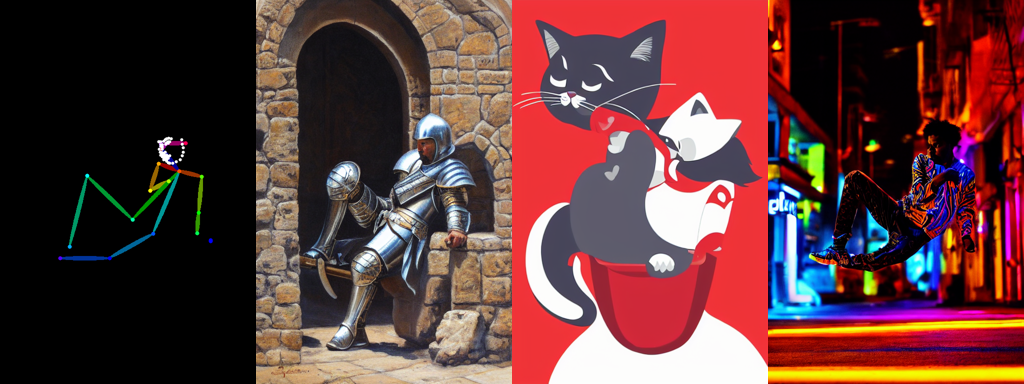

In [10]:
# 10-A) 같은 포즈 · 다른 프롬프트
PROMPTS_A = [
    "an old knight in silver armor in a castle courtyard, oil painting",
    "a cartoon cat character wearing a red hoodie, flat illustration, white background",
    "a street dancer in neon lights at night, cinematic photo",
]
outs_a = [pose_generate("pose_01", p, f"exp_a_{i+1}.png") for i, p in enumerate(PROMPTS_A)]
display(side_by_side(pose1, *outs_a))

Saving street dancer studio.jpg to street dancer studio.jpg
뼈대 저장: samples/pose_02.png  (512×640)
완료 (10.2초) → samples/output_02.png


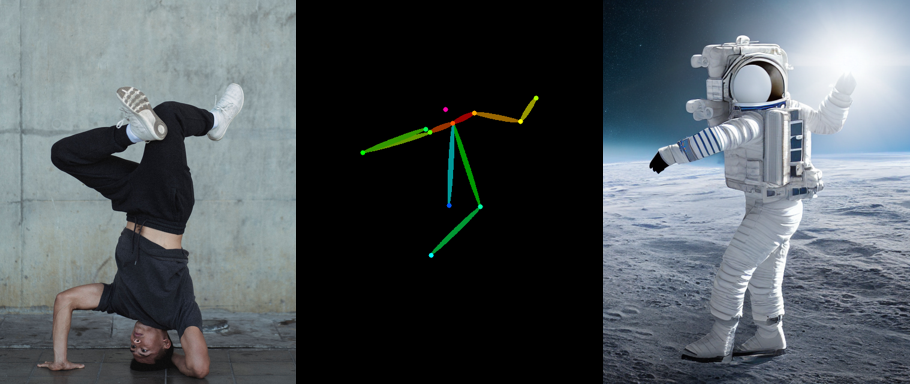

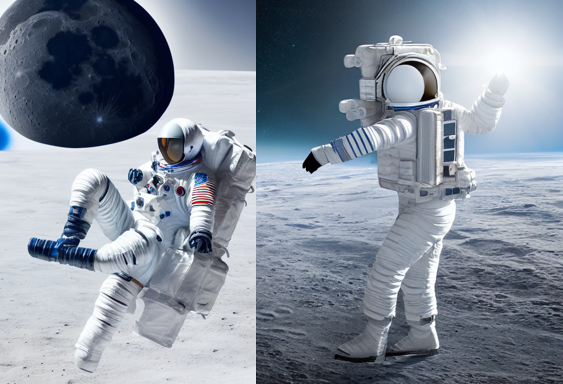

In [11]:
# 10-B) 다른 포즈 · 같은 프롬프트  ([파일 선택] 으로 자세가 확실히 다른 두 번째 사진을 올리세요)
ref2  = upload_photo("ref_02.jpg")
pose2 = extract_pose(ref2, "pose_02")
out2  = pose_generate("pose_02", PROMPT_1, "output_02.png")
display(side_by_side(ref2, pose2, out2))
display(side_by_side(out1, out2))          # 같은 프롬프트, 포즈만 다른 두 결과

완료 (10.5초) → samples/exp_c_strength_0.3.png
완료 (12.2초) → samples/exp_c_strength_0.6.png
완료 (12.2초) → samples/exp_c_strength_1.0.png


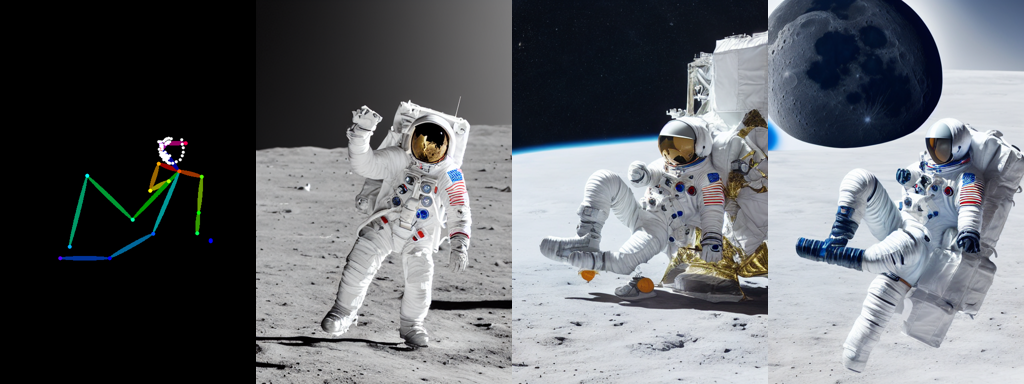

In [12]:
# 10-C) ControlNet 강도 바꾸기 (포즈를 따르는 힘)
outs_c = [pose_generate("pose_01", PROMPT_1, f"exp_c_strength_{s}.png", strength=s) for s in (0.3, 0.6, 1.0)]
display(side_by_side(pose1, *outs_c))

완료 (58.3초) → samples/exp_d_klein_reference.png


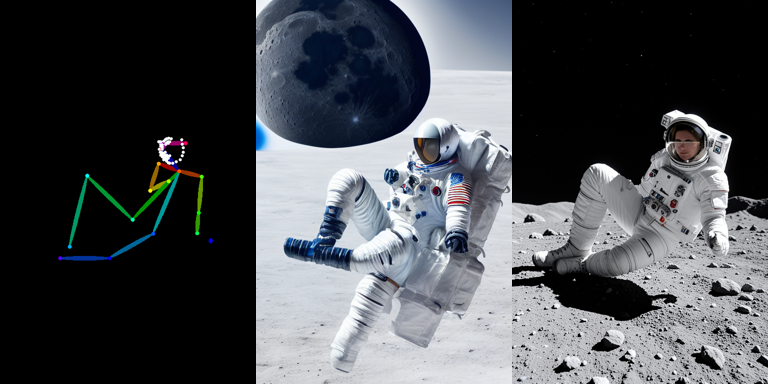

In [13]:
# 10-D) (선택) klein 의 참조 이미지 방식으로 뼈대를 넣어 보기 — ControlNet 과 비교
#       klein 은 포즈 전용 회로가 없어 뼈대를 "참고 그림" 으로만 봅니다. 잘 안 따라와도 그것 자체가 관찰 결과입니다.
klein_ref = klein_generate(
    "Draw the person in exactly the same pose as the stick figure in the reference image. " + PROMPT_1,
    "exp_d_klein_reference.png", width=pose1.width, height=pose1.height, reference_pose="pose_01")
display(side_by_side(pose1, out1, klein_ref))   # 뼈대 | ControlNet | klein 참조

## [단계 10-E] 개선판 도구: 어떤 사진이든 잘 나오도록

실험에서 본 실패 세 가지를 도구가 스스로 해결하게 만듭니다.

| 실험에서 본 실패 | 원인 | 개선판에서 하는 일 |
|---|---|---|
| 앉은 사진의 팔이 어색함 | 사람이 작아 관절이 뭉개짐 | ① 사람 영역 자동 크롭 + ② 1024 고해상도 추출 |
| 헤드스핀이 선 자세로 나옴 | OpenPose 가 위아래를 뒤집어 읽음 | ③ 0도·180도로 둘 다 뽑아 보고 관절을 더 확실하게 찾은 방향을 선택 |
| 시드마다 결과가 갈림 | 생성의 무작위성 | ④ 시드 4개로 생성 → 결과에서 다시 뼈대를 뽑아 원본 뼈대와 가장 닮은 것을 자동 선택 |

**자세 일치도 (0~1)**: 두 뼈대 그림의 선을 굵게 만든 뒤, **같은 색끼리** 겹친 면적을 전체 면적으로 나눈 값입니다. OpenPose 는 팔다리마다 색이 달라서 왼팔·오른팔이 뒤바뀐 경우도 낮은 점수가 나옵니다.

새 사진은 `pose_tool_v2(upload_photo("ref_03.jpg"), "프롬프트", "v2_pose_03")` 한 줄로 돌립니다. 사진 한 장에 1분 정도 걸립니다.

방향별 관절 점수: {0: np.float64(28.6), 180: 0.0} → 선택: 0 도
찾은 몸 관절: 17 / 18
완료 (8.1초) → samples/v2_pose_01_seed42.png
  시드 42: 자세 일치도 0.50
완료 (6.5초) → samples/v2_pose_01_seed7.png
  시드 7: 자세 일치도 0.35
완료 (6.6초) → samples/v2_pose_01_seed123.png
  시드 123: 자세 일치도 0.44
완료 (8.1초) → samples/v2_pose_01_seed2024.png
  시드 2024: 자세 일치도 0.47
선택: 시드 42 (일치도 0.50) → samples/v2_pose_01_best.png


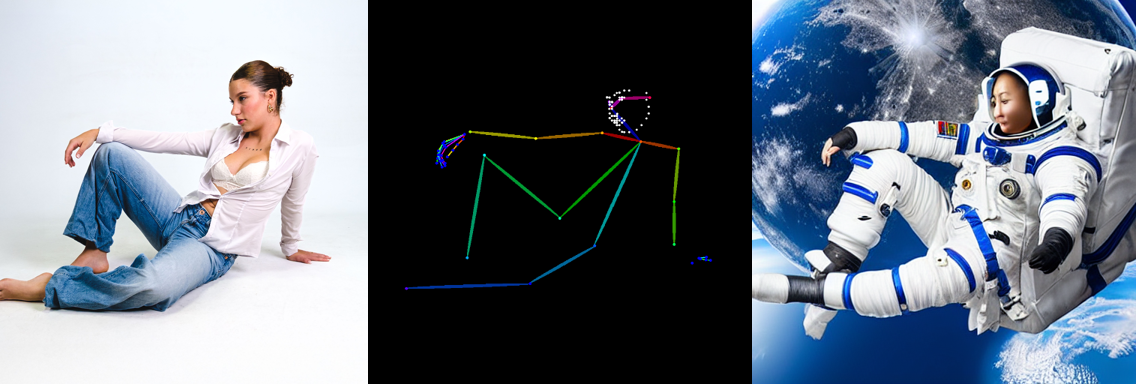

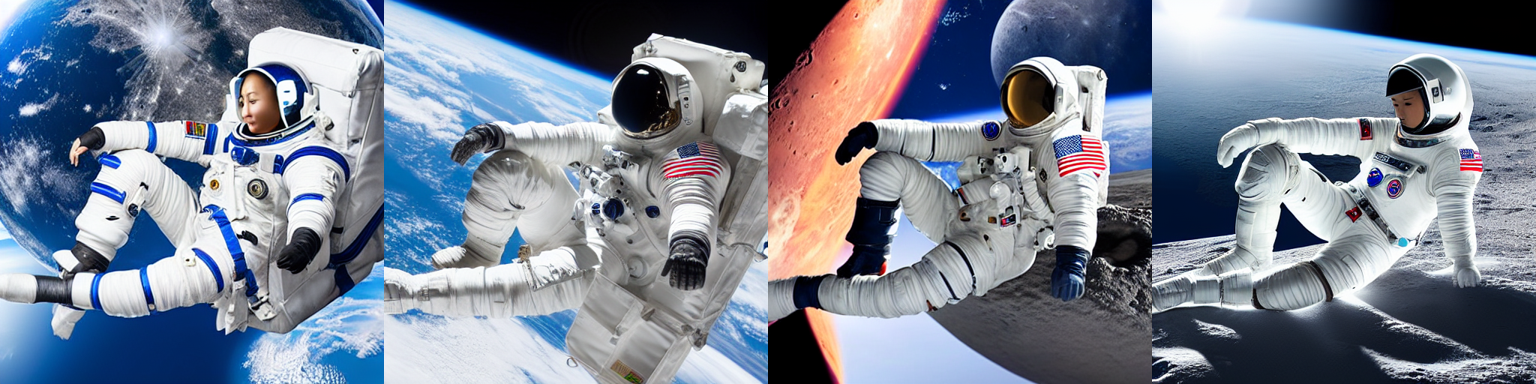

방향별 관절 점수: {0: np.float64(12.7), 180: np.float64(29.3)} → 선택: 180 도
찾은 몸 관절: 17 / 18
완료 (10.1초) → samples/v2_pose_02_seed42.png
  시드 42: 자세 일치도 0.22
완료 (10.1초) → samples/v2_pose_02_seed7.png
  시드 7: 자세 일치도 0.18
완료 (10.2초) → samples/v2_pose_02_seed123.png
  시드 123: 자세 일치도 0.00
완료 (10.2초) → samples/v2_pose_02_seed2024.png
  시드 2024: 자세 일치도 0.33
선택: 시드 2024 (일치도 0.33) → samples/v2_pose_02_best.png


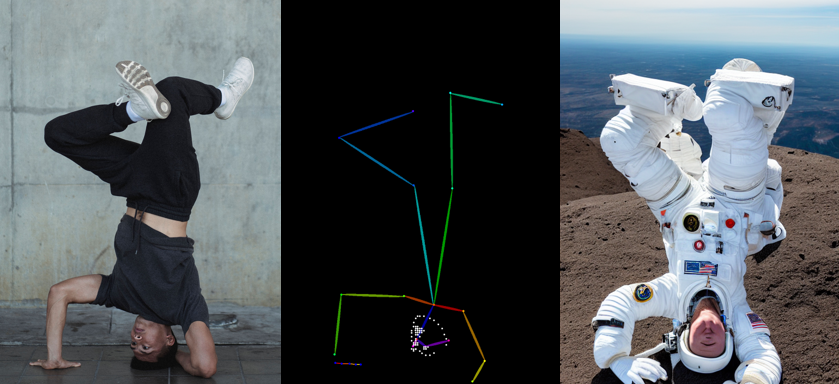

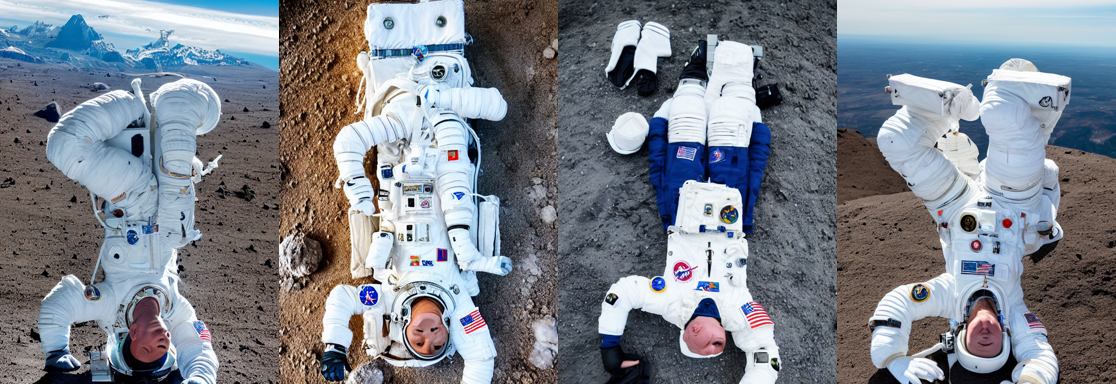

In [20]:
# 10-E) 개선판 포즈 도구 — 어떤 사진이든 잘 나오도록
#     ① 거꾸로 선 사진 자동 판별(회전)  ② 그 방향 기준으로 사람 영역 자동 크롭  ③ 고해상도(1024) 뼈대 추출
#     ④ 전신 구도 강제(얼굴 클로즈업 방지)  ⑤ 시드 여러 개로 생성 → 결과의 자세가 참조 뼈대와 가장 닮은 것을 자동 선택
import numpy as np, cv2
from PIL import ImageFilter
from controlnet_aux.open_pose import draw_poses
from controlnet_aux.util import HWC3, resize_image

NEG_V2 = (NEG_DEFAULT + ", deformed arm, twisted arm, extra arms, missing arm, extra legs, bad hands, fused limbs"
          ", close-up, portrait, headshot, face only, cropped body")      # 얼굴만 크게 나오는 결과 막기
FULL_BODY = "full body shot, wide shot, entire body visible from head to feet, "

def _detect(img, det_res=1024):
    """PIL 이미지 → (리사이즈된 배열, 사람별 관절 목록). 관절 좌표는 0~1 비율."""
    arr = resize_image(HWC3(np.array(img.convert("RGB"))), det_res)
    return arr, openpose.detect_poses(arr, include_hand=True, include_face=True)

def _draw(poses, shape, out_res=512, body_only=False):
    """관절 목록 → 검은 바탕 뼈대 그림 (짧은 변 out_res, 64의 배수)"""
    H, W = shape[:2]
    canvas = draw_poses(poses, H, W, draw_body=True, draw_hand=not body_only, draw_face=not body_only)
    h, w = resize_image(np.zeros((H, W, 3), np.uint8), out_res).shape[:2]
    return Image.fromarray(cv2.resize(HWC3(canvas), (w, h), interpolation=cv2.INTER_LINEAR))

def _main_body(poses):
    """가장 확실하게 잡힌 사람의 몸 관절 (없으면 None)"""
    return max((p.body for p in poses), key=lambda b: b.total_score, default=None)

def _quality(poses):
    """관절 신뢰도 합. 높을수록 관절을 많이, 확실하게 찾은 것."""
    b = _main_body(poses)
    return b.total_score if b else 0.0

def _n_joints(poses):
    """찾은 몸 관절 수 (최대 18)"""
    b = _main_body(poses)
    return sum(k is not None for k in b.keypoints) if b else 0

def _auto_crop(photo, poses, margin=0.2):
    """찾은 관절을 모두 감싸는 상자에 여백을 붙여 사람 중심으로 자릅니다."""
    pts = [k for p in poses for k in p.body.keypoints if k is not None]
    if len(pts) < 6:                       # 관절을 너무 적게 찾았으면 자르지 않음 (팔다리가 잘릴 위험)
        return photo
    xs, ys = [k.x for k in pts], [k.y for k in pts]
    x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)
    mx, my = (x1 - x0) * margin + 0.06, (y1 - y0) * margin + 0.10   # 머리끝·발끝이 잘리지 않게
    W, H = photo.size
    return photo.crop((int(max(0, x0 - mx) * W), int(max(0, y0 - my) * H),
                       int(min(1, x1 + mx) * W), int(min(1, y1 + my) * H)))

def _body_skeleton(img, rot, size):
    """이미지를 rot 만큼 돌려 몸 뼈대를 뽑고, 다시 원래 방향으로 돌린 그림 (채점용)"""
    arr, poses = _detect(img.rotate(rot, expand=True), 512)
    return _draw(poses, arr.shape, body_only=True).rotate(-rot, expand=True).resize(size)

def _similarity(ref_body, out_body):
    """두 뼈대 그림이 얼마나 겹치는지 (0~1). 선을 굵게 만든 뒤 같은 색(=같은 팔다리)끼리 겹친 비율."""
    a = np.asarray(ref_body.filter(ImageFilter.MaxFilter(15))).astype(int)
    b = np.asarray(out_body.filter(ImageFilter.MaxFilter(15))).astype(int)
    ma, mb = a.sum(2) > 60, b.sum(2) > 60
    union = (ma | mb).sum()
    same = ma & mb & (np.abs(a - b).sum(2) < 150)
    return float(same.sum() / union) if union else 0.0

def pose_tool_v2(photo, prompt, name, seeds=(42, 7, 123, 2024), strength=0.8, rotations=(0, 180), full_body=True):
    """사진 + 프롬프트 → 같은 자세의 결과. 후보를 여러 장 만들고 자세가 가장 닮은 것을 고릅니다.
    실행 정보(선택한 방향, 관절 수, 일치도, 경고)는 pose_tool_v2.info 에 남습니다."""
    warnings = []

    # ① 원본 전체를 0도·180도로 돌려 보고, 관절을 가장 확실하게 찾은 방향을 고름 (0도보다 20% 이상 좋을 때만 회전)
    tried = {r: _detect(photo.rotate(r, expand=True), 768)[1] for r in rotations}
    scores = {r: _quality(p) for r, p in tried.items()}
    best_r = max(scores, key=scores.get)
    if best_r != 0 and scores[best_r] < scores[0] * 1.2:
        best_r = 0
    print("방향별 관절 점수:", {r: round(s, 1) for r, s in scores.items()}, "→ 선택:", best_r, "도")

    # ② 고른 방향 기준으로 사람 영역을 잘라 ③ 고해상도로 다시 추출
    rotated = photo.rotate(best_r, expand=True)
    crop    = _auto_crop(rotated, tried[best_r])
    arr, poses = _detect(crop, 1024)
    n = _n_joints(poses)
    print(f"찾은 몸 관절: {n} / 18")
    if n == 0:
        warnings.append("사람을 찾지 못했습니다. 다른 사진을 써 보세요.")
    elif n < 10:
        warnings.append(f"몸 관절을 {n}개밖에 못 찾았습니다. 팔다리가 가려지지 않은 사진일수록 정확합니다.")

    skel     = _draw(poses, arr.shape).rotate(-best_r, expand=True)                 # 생성 조건용 (손·얼굴 포함)
    ref_body = _draw(poses, arr.shape, body_only=True).rotate(-best_r, expand=True) # 채점용 (몸만)
    skel.save(os.path.join(SAMPLES, f"{name}.png"))
    skel.save(os.path.join(COMFY_INPUT, f"{name}.png"))

    # ④ 전신 구도 문구를 앞에 붙여 얼굴 클로즈업을 막고 ⑤ 시드마다 생성 → 결과에서 다시 뼈대를 뽑아 비교
    full_prompt = (FULL_BODY + prompt) if full_body else prompt
    results = []
    for s in seeds:
        out = pose_generate(name, full_prompt, f"{name}_seed{s}.png", negative=NEG_V2, strength=strength, seed=s)
        sim = _similarity(ref_body, _body_skeleton(out, best_r, ref_body.size))
        results.append((sim, s, out))
        print(f"  시드 {s}: 자세 일치도 {sim:.2f}")
    sim, s, best = max(results, key=lambda t: t[0])
    best.save(os.path.join(SAMPLES, f"{name}_best.png"))
    print(f"선택: 시드 {s} (일치도 {sim:.2f}) → samples/{name}_best.png")
    if sim < 0.2:
        warnings.append(f"가장 닮은 결과도 일치도가 {sim:.2f}로 낮습니다. 프롬프트에 자세를 직접 적어 보세요 "
                        "(예: doing a headstand, upside down, legs in the air).")
    for w in warnings:
        print("경고:", w)

    pose_tool_v2.info = {"rotation": best_r, "joints": n, "seed": s, "similarity": sim, "warnings": warnings}
    display(side_by_side(crop.rotate(-best_r, expand=True), skel, best))   # 자른 사진 | 뼈대 | 최종 선택
    display(side_by_side(*[o for _, _, o in results]))                    # 후보 전체
    return best

# 사용 예: 앞에서 올린 두 사진을 개선판으로 다시 만들기
best1 = pose_tool_v2(ref1, PROMPT_1, "v2_pose_01")
best2 = pose_tool_v2(ref2, "an astronaut in a white spacesuit doing an upside-down breakdance headstand freeze on the moon, "
                           "head on the ground, legs in the air", "v2_pose_02")

## [단계 11] (선택) 나만의 포즈 도구 UI

원본 노트의 Gradio UI 를 포즈 도구용으로 바꿨습니다. 사진을 올리고 프롬프트를 쓰면 **뼈대와 결과** 가 함께 나옵니다. 실행하면 `gradio.live` 로 끝나는 임시 공개 링크가 나오고, 이 셀이 실행 중일 때만 열립니다.

In [21]:
# 11) Gradio UI — 사진 + 프롬프트 → 개선판 도구(10-E)로 뼈대 + 가장 닮은 결과
#     10-E 셀을 먼저 실행해야 합니다 (pose_tool_v2 를 씁니다).
import gradio as gr, time

UI_PROMPT = ("an astronaut in a white spacesuit doing an upside-down breakdance headstand freeze on the moon, "
             "head on the ground, legs in the air")

def ui_run(photo, prompt, strength, n_seeds, first_seed):
    if photo is None:
        return None, None, None, "사진을 먼저 올려 주세요."
    name  = f"ui_{int(time.time())}"                                   # 실행마다 다른 이름으로 저장
    seeds = tuple(int(first_seed) + i for i in range(int(n_seeds)))     # 예: 42, 43, 44, 45
    best  = pose_tool_v2(photo.convert("RGB"), prompt, name, seeds=seeds, strength=strength)
    info  = pose_tool_v2.info
    skel  = Image.open(os.path.join(SAMPLES, f"{name}.png"))
    cands = [Image.open(os.path.join(SAMPLES, f"{name}_seed{s}.png")) for s in seeds]
    msg = (f"완료 — 방향 {info['rotation']}도, 몸 관절 {info['joints']}/18, "
           f"후보 {len(seeds)}장 중 시드 {info['seed']} 선택 (자세 일치도 {info['similarity']:.2f})")
    msg += "".join(f"\n\n**경고**: {w}" for w in info["warnings"])
    return skel, best, cands, msg

with gr.Blocks() as demo:
    gr.Markdown("# 원하는 포즈로 이미지 만들기 (개선판)\n"
                "사람 사진을 올리고 프롬프트를 쓰면, 여러 장을 만들어 자세가 가장 닮은 결과를 골라 줍니다.\n\n"
                "**팁**: 거꾸로 서기·점프처럼 흔하지 않은 자세는 프롬프트에 자세를 직접 적으면 훨씬 잘 따릅니다 "
                "(예: `doing a headstand, upside down, legs in the air`).")
    with gr.Row():
        with gr.Column():
            photo      = gr.Image(label="참조 사진", type="pil")
            prompt     = gr.Textbox(label="프롬프트 (누가·어디서 + 자세 설명)", value=UI_PROMPT, lines=2)
            strength   = gr.Slider(0.0, 1.5, value=0.8, step=0.1, label="포즈 강도 (ControlNet strength)")
            n_seeds    = gr.Slider(1, 6, value=4, step=1, label="후보 수 (많을수록 정확하지만 느림, 1장당 약 10초)")
            first_seed = gr.Number(value=42, label="시작 시드")
            btn        = gr.Button("생성", variant="primary")
            status     = gr.Markdown("")
        with gr.Column():
            pose_out = gr.Image(label="추출된 뼈대 (자동 크롭·방향 보정)")
            img_out  = gr.Image(label="최종 선택")
    gallery = gr.Gallery(label="후보 전체", columns=6, height="auto")
    btn.click(ui_run, [photo, prompt, strength, n_seeds, first_seed], [pose_out, img_out, gallery, status])

gr.close_all()                      # 앞서 띄운 UI 가 포트를 잡고 있으면 먼저 닫음
demo.launch(share=True, quiet=True)  # 포트는 Gradio 가 빈 곳으로 자동 선택

Closing server running on port: 7860
* Running on public URL: https://f60ac7b4f9a7e1a606.gradio.live


## [단계 12] 결과 정리와 내려받기

`samples/` 폴더를 zip 으로 묶어 내려받습니다. GitHub 저장소의 `samples/` 에 압축을 풀어 올리면 됩니다.

내려받은 뒤 이 노트도 **[파일 → 다운로드 → .ipynb 다운로드]** 로 저장하세요. 결과 이미지가 노트 안에 보이도록 **셀을 실행한 상태로** 저장해야 합니다.

In [22]:
# 12) samples 폴더를 zip 으로 묶어 내려받기 (GitHub 업로드용)
import shutil
!ls -lh /content/samples
shutil.make_archive("/content/samples", "zip", SAMPLES)
files.download("/content/samples.zip")

total 21M
-rw-r--r-- 1 root root 534K Nov 11 07:11 baseline_klein_no_pose.png
-rw-r--r-- 1 root root 810K Nov 11 07:12 exp_a_1.png
-rw-r--r-- 1 root root 266K Nov 11 07:12 exp_a_2.png
-rw-r--r-- 1 root root 528K Nov 11 07:12 exp_a_3.png
-rw-r--r-- 1 root root 572K Nov 11 07:14 exp_c_strength_0.3.png
-rw-r--r-- 1 root root 624K Nov 11 07:14 exp_c_strength_0.6.png
-rw-r--r-- 1 root root 598K Nov 11 07:14 exp_c_strength_1.0.png
-rw-r--r-- 1 root root 529K Nov 11 07:19 exp_d_klein_reference.png
-rw-r--r-- 1 root root 598K Nov 11 07:08 output_01.png
-rw-r--r-- 1 root root 552K Nov 11 07:14 output_02.png
-rw-r--r-- 1 root root 5.1K Nov 11 07:01 pose_01.png
-rw-r--r-- 1 root root 3.5K Nov 11 07:13 pose_02.png
-rw-r--r-- 1 root root 1.7M Nov 11 07:00 ref_01.jpg
-rw-r--r-- 1 root root 2.2M Nov 11 07:13 ref_02.jpg
-rw-r--r-- 1 root root 382K Nov 11 08:00 ui_1794383849_best.png
-rw-r--r-- 1 root root 7.1K Nov 11 07:59 ui_1794383849.png
-rw-r--r-- 1 root root 382K Nov 11 07:59 ui_1794383849_seed42

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 실험 기록: 무엇을 바꿔 보았고, 어떻게 달라졌는가

모든 실험은 SD 1.5 + ControlNet OpenPose, seed 42, 25 steps, cfg 7.0 으로 하고 **한 번에 조건 하나만** 바꿨습니다(실험 E 제외).

- **참조 사진 1 (`pose_01`)**: 바닥에 앉아 상체를 뒤로 기대고, 한쪽 무릎을 세워 그 위에 팔을 올리고, 다른 팔로 바닥을 짚은 자세
- **참조 사진 2 (`pose_02`)**: 브레이크댄스 헤드스핀. 머리와 팔로 바닥을 짚고 다리를 공중에 벌린 거꾸로 선 자세
- **참조 사진 3 (UI 실험)**: 같은 댄서의 다른 헤드스핀 사진. 다리를 공중에서 꼰 자세

### 기본 결과 (`output_01.png`)
- 바닥에 앉아 뒤로 기대고, 무릎을 세우고, 팔로 바닥을 짚은 **큰 자세는 그대로 따라왔습니다.**
- 참조 사진은 두 다리를 모두 굽혀 발을 바닥에 댔지만, 결과에서는 한쪽 다리가 앞으로 뻗어 떠 있는 모습이었습니다.
- 뼈대 그림에서 **무릎 위에 올린 팔이 다리와 겹쳐 제대로 잡히지 않았고**, 그 팔이 결과에서 가장 어색했습니다.
- 우주복, 달 표면, 행성 같은 **내용과 배경은 프롬프트를 따랐습니다.** 자세는 뼈대가, 내용은 프롬프트가 정한다는 역할 분담이 보였습니다.

### 0. 포즈 조건 유무 (`output_01.png` vs `baseline_klein_no_pose.png`)
- 같은 프롬프트를 포즈 조건 없이 klein 으로 그리자, 우주비행사가 **정면을 보고 두 팔을 내린 채 똑바로 서 있는** 모습이 나왔습니다. 참조 사진의 앉은 자세와는 전혀 달랐습니다.
- 이 자세는 프롬프트의 `standing on the moon` 을 그대로 따른 결과입니다. **포즈 조건이 없으면 자세는 프롬프트의 단어와 모델이 가장 흔하게 본 구도(정면 전신)로 정해졌습니다.**
- 포즈 조건을 넣은 `output_01.png` 는 같은 프롬프트에 `standing` 이 있는데도 **앉아서 뒤로 기댄 자세**가 나왔습니다. 프롬프트와 뼈대가 부딪칠 때 **자세는 뼈대가 이겼고**, 우주복·달 배경 같은 내용은 두 결과 모두 프롬프트를 따랐습니다.
- 단, 두 결과는 모델이 다릅니다(SD 1.5 vs FLUX.2-klein). 그래도 klein 이 실험 D 에서 뼈대를 참조로 넣었을 때 앉은 자세를 따랐으므로, 자세 차이는 모델 차이보다 **포즈 조건 유무** 때문이라고 볼 수 있습니다.

### A. 같은 포즈 · 다른 프롬프트 (`exp_a_1~3.png`)

| 파일 | 프롬프트 | 자세 | 관찰 |
|---|---|---|---|
| `exp_a_1.png` | 은빛 갑옷의 기사, 유화 | 잘 따름 | 기대어 앉고 무릎을 굽힌 자세 유지. 다만 바닥이 아니라 돌 턱에 걸터앉은 모습으로 바뀜 |
| `exp_a_2.png` | 빨간 후드티 만화 고양이 | 거의 무시 | 사람 자세가 사라지고 고양이 두 마리와 빨간 통이 나옴. `white background` 도 무시되고 빨간 배경 |
| `exp_a_3.png` | 네온 거리의 댄서 | 대체로 따름 | 다리를 굽히고 뒤로 기댄 자세는 비슷하지만 바닥 없이 공중에 떠 있음 |

- **사람을 그리는 프롬프트에서는 자세가 유지되고, 사람이 아닌 대상에서는 자세 조건이 거의 먹히지 않았습니다.** OpenPose 뼈대는 사람의 관절 구조라서 고양이 몸에 대응시킬 곳이 없었던 것으로 보입니다.
- 뼈대에는 관절 위치만 있고 바닥이나 의자 정보는 없어서, **어디에 앉았는지는 프롬프트와 장면에 따라 달라졌습니다** (바닥, 돌 턱, 공중).
- 화풍(유화, 플랫 일러스트, 네온 사진)은 프롬프트가 거의 그대로 결정했습니다.

### B. 다른 포즈 · 같은 프롬프트 (`output_01.png` vs `output_02.png`)
- 포즈 사진만 헤드스핀으로 바꾸자, 결과는 **팔을 양옆으로 벌리고 똑바로 선 우주비행사**가 나왔습니다. 헤드스핀 자세가 아니었습니다.
- 뼈대 그림을 보니 **OpenPose 가 거꾸로 선 사람을 똑바로 선 사람으로 잘못 읽었습니다.**
  - 공중으로 벌린 두 다리 → 양옆으로 벌린 두 팔
  - 바닥을 짚은 팔 → 아래로 뻗은 다리
  - 바닥에 닿은 머리 → 거의 못 찾음
- ControlNet 은 받은 뼈대를 충실히 따랐습니다. **실패는 생성 단계가 아니라 포즈 추출 단계에서 일어났습니다.** 이 도구는 추출과 생성 두 단계로 되어 있어서, 어느 단계에서 틀렸는지 나눠 봐야 원인을 찾을 수 있다는 것을 알게 됐습니다.
- 인물(우주복)과 배경(달)은 포즈가 바뀌어도 유지되어, 포즈 조건이 자세만 바꾼다는 것은 확인했습니다.

### C. ControlNet 강도 (`exp_c_strength_0.3 / 0.6 / 1.0.png`)

| 강도 | 자세 | 관찰 |
|---|---|---|
| 0.3 | 무너짐 | 앉은 자세가 사라지고 손을 든 채 서 있는 우주비행사. 조건이 약하면 모델이 익숙한 기본 자세로 돌아감 |
| 0.6 | 대체로 따름 | 무릎을 굽히고 몸을 기울인 자세가 유지되면서 발이 땅에 닿아 가장 자연스러움 |
| 1.0 | 가장 정확 | 뼈대와 가장 가깝지만 몸이 땅에서 떠 보여 어색함 |

- 강도 0.3 과 0.6 사이에서 자세가 무너졌습니다.
- **강도가 셀수록 자세는 정확해지지만 자연스러움은 떨어졌습니다.** 레슨에서 배운 "조건을 따르는 힘과 자연스러움 사이의 균형"이 가이던스뿐 아니라 ControlNet 강도에서도 똑같이 나타났습니다.
- 강도 1.0 결과는 `output_01.png` 와 똑같았습니다. 시드를 42 로 고정했기 때문이고, **조건이 같으면 결과도 같다는 재현성**을 확인했습니다.

### D. klein 참조 이미지 방식 (`exp_d_klein_reference.png`)
- 포즈 전용 회로가 없는 FLUX.2-klein 에 뼈대 그림을 참조 이미지로 넣었는데, **앉아서 뒤로 기대고 무릎을 세우고 팔로 바닥을 짚은 큰 자세를 꽤 잘 따랐습니다.**
- ControlNet 강도 1.0 결과는 몸이 떠 보였지만, klein 결과는 **엉덩이와 발이 땅에 제대로 닿아 더 자연스러웠습니다.**
- 다리 모양은 뼈대와 조금 달랐습니다(한쪽 다리를 앞으로 뻗음). **관절 하나하나의 정확도는 ControlNet 이 더 높아 보였습니다.**
- 뼈대의 색깔 선을 그림에 베껴 넣지 않고 자세 정보로만 썼습니다.
- 단, **포즈 1장·시드 1개로 본 결과**라 일반화하기는 이릅니다.

### E. 개선판 도구 (10-E, 11)
실험 기본 결과·A~D 에서 본 실패 원인을 도구가 스스로 해결하도록 바꿨습니다.

| 실험에서 본 실패 | 원인 | 개선 |
|---|---|---|
| 앉은 사진의 팔이 어색함 (기본 결과) | 사람이 작아 관절이 뭉개짐, 팔과 다리가 겹침 | 사람 영역 자동 크롭 + 1024 고해상도 추출 |
| 헤드스핀이 선 자세로 나옴 (B) | OpenPose 가 위아래를 뒤집어 읽음 | 0도·180도로 둘 다 뽑아 관절을 더 확실하게 찾은 방향을 고른 뒤 그 방향 기준으로 크롭 |
| 헤드스핀이 얼굴 클로즈업으로 나옴 (첫 UI 시도) | 프롬프트의 standing 과 뼈대가 충돌, 모델이 초상화 구도로 도망감 | 전신 구도 문구 자동 추가 + 클로즈업을 네거티브에 추가 + 프롬프트에 자세 직접 서술 |
| 강도 1.0 의 어색함, 시드마다 갈리는 결과 (C) | 조건 과다, 생성의 무작위성 | 강도 0.8 + 시드 4개 생성 후 자세 일치도가 가장 높은 결과 자동 선택 |

#### E-1. 앉은 사진 (`v2_pose_01_best.png`)
- **방향 판별**: 방향 점수 0도 28.6, 180도 0.0 으로 **0도(회전 없음)를 그대로 유지**했고, 몸 관절은 **17/18개** 찾았습니다. 똑바로 앉은 사진은 쓸데없이 뒤집지 않아, 회전이 필요한 사진에서만 작동한다는 것을 확인했습니다.
- **자세 일치도**: 시드 42 **0.50**, 시드 7 0.35, 시드 123 0.44, 시드 2024 0.47 로 **시드 42 가 선택됐습니다.** 같은 뼈대·프롬프트라도 시드에 따라 0.35~0.50 으로 갈려, 여러 장을 만들어 고르는 방식이 효과가 있었습니다.
- **개선 전후 비교**
  - 개선 전 뼈대는 무릎 위에 올린 팔을 거의 못 잡았는데, 자동 크롭과 1024 해상도 추출 뒤에는 **무릎 위에 걸친 팔과 손까지 뼈대에 나타났습니다.**
  - 그 결과 후보 4장 모두 **팔뚝을 세운 무릎 위에 올리고 다른 팔로 몸을 받친** 자세가 나와, 개선 전 가장 어색했던 팔이 참조 사진과 같아졌습니다.
- **남은 한계**: 배경이 달 표면이 아니라 우주 공간이 된 후보가 많았고, 몸이 바닥에 앉기보다 떠 있는 듯한 모습이 남았습니다. 뼈대에 바닥 정보가 없다는 실험 A 의 관찰과 같은 한계입니다.

#### E-2. 헤드스핀 사진 (`ui_*_best.png`, 참조 사진 3)
- **방향 판별**: **180도를 선택**했고 몸 관절을 **17/18개** 찾았습니다. 개선 전(10-B)에는 같은 종류의 헤드스핀 사진을 0도 그대로 읽어 똑바로 선 사람으로 오인식했습니다.
- **자세 일치도**: 후보 4장(시드 42~45) 중 **시드 43 이 0.27 로 가장 높았고**, 눈으로 봐도 다리를 공중에 들고 머리를 땅에 댄 모습이 가장 깔끔했습니다. 자동 선택이 사람의 판단과 일치했습니다.
- **개선 전후 비교**: 개선 전에는 팔을 벌리고 선 자세(10-B)나 헬멧 얼굴 클로즈업(첫 UI 시도)이 나왔지만, 개선 후에는 **후보 4장 모두 머리가 아래·다리가 위인 거꾸로 선 자세**가 나왔습니다.
- **남은 한계**
  - 참조 사진은 다리를 **꼬았는데** 결과는 **V자로 벌렸습니다.** 꼬인 다리처럼 겹친 관절은 뼈대만으로 앞뒤를 구분하기 어렵습니다.
  - 선택되지 않은 후보들은 몸통과 팔이 뒤엉켜 해부학적으로 어색했습니다. **추출은 성공했지만 SD 1.5 가 거꾸로 선 사람을 잘 그리지 못하는 생성 쪽 한계**로 보입니다.
  - 일치도 0.27 은 높은 값이 아니어서, 방향은 맞췄지만 관절 하나하나까지 맞춘 것은 아닙니다.

#### E 정리
- 앉은 사진의 일치도(0.50)가 헤드스핀(0.27)보다 높게 나와, **흔한 자세일수록 추출과 생성이 모두 잘 된다**는 것이 숫자로도 확인됐습니다.
- 실패 원인을 **추출 단계와 생성 단계로 나눠** 보니 고칠 곳이 보였습니다. 추출 쪽 문제(방향, 크롭, 가려진 팔)는 코드로 해결됐고, 생성 쪽 문제(거꾸로 선 해부학, 바닥 접촉)는 더 큰 모델(SDXL 등)이나 다른 조건(Depth)이 필요한 부분으로 남았습니다.

### 정리
- **결과를 더 크게 바꾼 쪽**: 무엇을 그리는지(인물, 옷, 배경, 화풍)는 **프롬프트**가, 몸이 어떤 모양인지는 **포즈**가 결정했습니다. 단, 사람이 아닌 대상을 프롬프트로 지정하면 프롬프트가 포즈를 이겼습니다.
- **잘 따라온 것**: 앉기, 기대기, 무릎 세우기, 바닥 짚기처럼 **팔다리 전체가 움직이는 큰 자세**
- **잘 안 따라온 것**
  - 다리와 겹친 팔처럼 **가려지거나 겹친 관절**
  - 거꾸로 선 자세처럼 **흔하지 않은 방향의 자세**
  - **사람이 아닌 대상**
  - 바닥에 닿는 느낌처럼 **뼈대에 없는 정보**
- **배운 점**
  - 포즈 도구는 **추출과 생성 두 단계**로 되어 있어서, 결과가 틀렸을 때 뼈대 그림부터 확인해야 원인이 보입니다.
  - 조건의 세기는 **정확도와 자연스러움을 맞바꾸는 값**이라 가장 센 값이 가장 좋은 값은 아니었습니다.
- **다음에 해 볼 것**
  - 해부학 표현이 더 좋은 **SDXL + ControlNet OpenPose** 로 바꿔 손과 겹친 팔다리 비교
  - 포즈와 **Depth(깊이) ControlNet 을 함께 넣어** 바닥에 닿는 느낌 보완
  - klein 참조 방식을 **여러 포즈·시드로 반복**해 실험 D 를 일반화